In [4]:
import os
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Cấu hình thiết bị và siêu tham số
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"--> Thiết bị đang chạy: {device}")

BATCH_SIZE = 128      # Kích thước batch tối ưu cho CPU
IMG_SIZE = 48
NUM_CLASSES = 7
EPOCHS = 3            # Chạy thử nghiệm 3 epoch trên CPU
LR = 0.001

# 2. Tiền xử lý dữ liệu (Grayscale 1 kênh màu)
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

TRAIN_DIR = r"../data/raw/train"
TEST_DIR = r"../data/raw/test"

train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=train_transform)
test_dataset = datasets.ImageFolder(root=TEST_DIR, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

classes = train_dataset.classes
print(f"--> Tổng mẫu Train: {len(train_dataset)} | Tổng mẫu Test: {len(test_dataset)}")
print(f"--> Danh sách 7 nhãn: {classes}")

--> Thiết bị đang chạy: cpu
--> Tổng mẫu Train: 28709 | Tổng mẫu Test: 7178
--> Danh sách 7 nhãn: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [5]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(BaselineCNN, self).__init__()
        # Block 1: 48x48 -> 24x24
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2, 2)
        
        # Block 2: 24x24 -> 12x12
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        
        # Block 3: 12x12 -> 6x6
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        
        # Classifier
        self.fc1 = nn.Linear(128 * 6 * 6, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

model = BaselineCNN(num_classes=NUM_CLASSES).to(device)
print(model)

BaselineCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc1): Linear(in_features=4608, out_features=256, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=7, bias=True)
)


In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

os.makedirs("../checkpoints", exist_ok=True)
os.makedirs("../results/plots", exist_ok=True)

train_losses = []
test_accuracies = []
best_acc = 0.0

print("--- BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH BASELINE ---")
for epoch in range(EPOCHS):
    start_time = time.time()
    model.train()
    running_loss = 0.0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        
    epoch_loss = running_loss / len(train_dataset)
    train_losses.append(epoch_loss)
    
    # Đánh giá nhanh trên tập test
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
    val_acc = 100.0 * correct / total
    test_accuracies.append(val_acc)
    elapsed = time.time() - start_time
    
    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | Time: {elapsed:.1f}s | Train Loss: {epoch_loss:.4f} | Test Acc: {val_acc:.2f}%")
    
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), "../checkpoints/baseline_best.pth")

print(f"\n--> Huấn luyện xong! Best Test Acc: {best_acc:.2f}%")
print("--> Trọng số tốt nhất đã được lưu vào: ../checkpoints/baseline_best.pth")

--- BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH BASELINE ---
Epoch [01/3] | Time: 261.0s | Train Loss: 1.7818 | Test Acc: 39.73%
Epoch [02/3] | Time: 74.3s | Train Loss: 1.5566 | Test Acc: 43.22%
Epoch [03/3] | Time: 77.3s | Train Loss: 1.4623 | Test Acc: 48.34%

--> Huấn luyện xong! Best Test Acc: 48.34%
--> Trọng số tốt nhất đã được lưu vào: ../checkpoints/baseline_best.pth


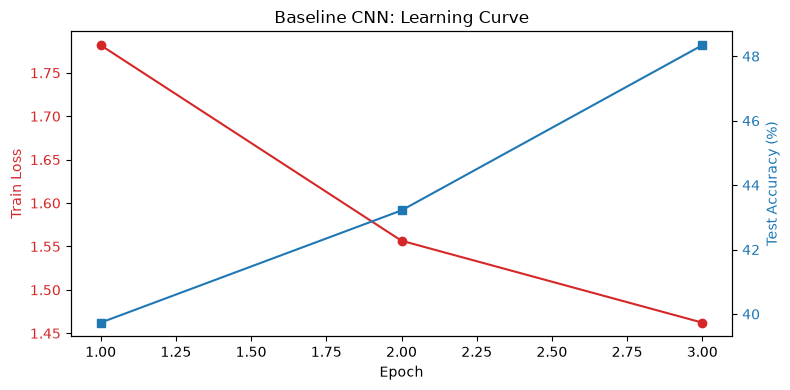

--> Đã lưu biểu đồ Learning Curve vào results/plots/baseline_learning_curve.png!


In [7]:
fig, ax1 = plt.subplots(figsize=(8, 4))

color = "tab:red"
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Train Loss", color=color)
ax1.plot(range(1, EPOCHS + 1), train_losses, color=color, marker="o", label="Train Loss")
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()
color = "tab:blue"
ax2.set_ylabel("Test Accuracy (%)", color=color)
ax2.plot(range(1, EPOCHS + 1), test_accuracies, color=color, marker="s", label="Test Acc")
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Baseline CNN: Learning Curve")
plt.tight_layout()
plt.savefig("../results/plots/baseline_learning_curve.png", dpi=300)
plt.show()
print("--> Đã lưu biểu đồ Learning Curve vào results/plots/baseline_learning_curve.png!")


--- BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ---
              precision    recall  f1-score   support

       angry       0.41      0.15      0.22       958
     disgust       0.00      0.00      0.00       111
        fear       0.27      0.08      0.12      1024
       happy       0.58      0.86      0.69      1774
     neutral       0.41      0.61      0.49      1233
         sad       0.35      0.36      0.36      1247
    surprise       0.68      0.61      0.65       831

    accuracy                           0.48      7178
   macro avg       0.39      0.38      0.36      7178
weighted avg       0.45      0.48      0.44      7178



c:\Users\admin\anaconda3\envs\fer_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\admin\anaconda3\envs\fer_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\admin\anaconda3\envs\fer_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

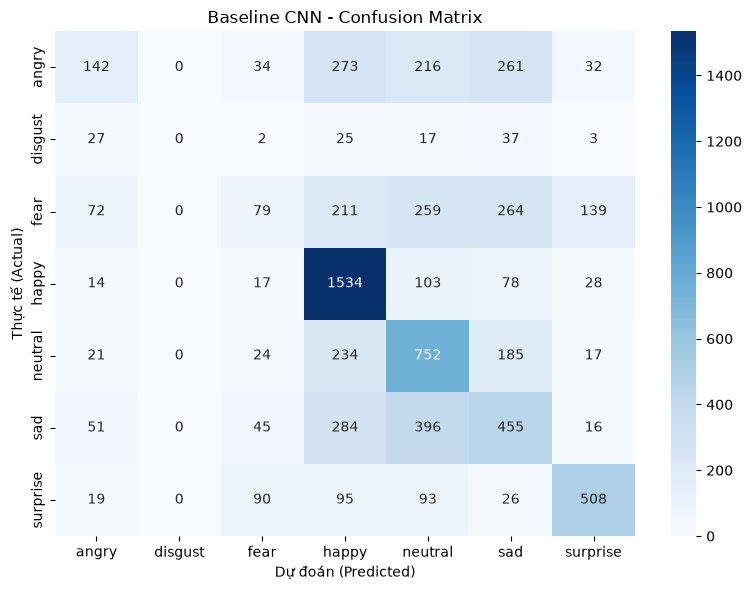

--> Đã lưu ma trận nhầm lẫn vào results/plots/baseline_confusion_matrix.png!


In [8]:
# Tải lại trọng số tốt nhất đã lưu
model.load_state_dict(torch.load("../checkpoints/baseline_best.pth"))
model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

print("\n--- BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ---")
print(classification_report(all_targets, all_preds, target_names=classes))

# Vẽ Confusion Matrix Heatmap
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Baseline CNN - Confusion Matrix")
plt.xlabel("Dự đoán (Predicted)")
plt.ylabel("Thực tế (Actual)")
plt.tight_layout()
plt.savefig("../results/plots/baseline_confusion_matrix.png", dpi=300)
plt.show()
print("--> Đã lưu ma trận nhầm lẫn vào results/plots/baseline_confusion_matrix.png!")